<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/M3_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group 11 Assignment 1 – Milestone 3 (EDA)

## Bike Share Station Demand for Growth Planning

### Notes

There are a few changes to our project since Milestone 2:

1. City of Toronto Open Data Catalogue: Bike Share Toronto Ridership Data only has data from January to March for the planned test year 2026. This means that we will not have enough data to use 2026 as our test set. Our new training and test set will be as follows:

- Training: January 2023 - December 2024
- Test: January 2025 - December 2025, with January 2026 - March 2026 as an extra test check for the first quarter findings

2. Instead of seasons, we will look at demand patterns by quarters of the year:

- Q1: January-March
- Q2: April-June
- Q3: July-September
- Q4: October-December

3. Weather Data
- For each Toronto Bike Share station we use the latitude and longitude of the bike stations along with the latitude and longitude of the Environment Canada weather stations to find the nearest weather station for each bike station.
- We calculate the distance between both set of latitudes and latitudes using Haversine formula, which helps measure distance between two geographical points.
- For each bike station, we identify the nearest neighbouring bike station, excluding the station itself, and record its name and distance in kilometres.
- Currently we have the code that stores this information in a separate excel file. We have not included the weather data in this report because that will be cleaned separately and the merging of that data doesn't affect our decisions about the target variable we chose. We will add the cleaned weather data in the next milestone report.



Note on AI use:
- The steps we took and the observations and findings are our understanding, but much of the code was done with the use of AI, especially in section 3, which applied our observations on the sample months to the rest of the dataset.

### Milestone 3 Objectives

The purpose of this milestone is to explore, understand, and validate the dataset before applying
any machine learning models.

The first part of this notebook explores the dataset without doing any cleaning yet, and uses the observations to propose the rules that we will use to clean the data.

Since we are working with a very large dataset, we first take a look at some sample months, then apply the initial findings on the full set of 39 months to help analyze the data.

In [1]:
# Import libraries
import os, glob, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

In [2]:
# Where the data is (works in Colab and on a laptop)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"    # shared Drive folder
else:
    DATA = "../data"

RAW = f"{DATA}/raw" # raw datasets
PROFILE = f"{DATA}/profile" # outputs to help with profiling the data go here
os.makedirs(PROFILE, exist_ok=True)
print("Raw data folder:", RAW)

Mounted at /content/drive
Raw data folder: /content/drive/MyDrive/DataSets/raw


## 1. One Month Per Year
- Check January and July months for each year available

### 1.1 Load the sample months

In [3]:
sample_paths = {
    "2023-01": f"{RAW}/2023/Bike share ridership 2023-01.csv",
    "2024-01": f"{RAW}/2024/bikeshare-ridership-2024-01_Jan.csv",
    "2024-07": f"{RAW}/2024/bikeshare-ridership-2024-07_Jul.csv",
    "2025-01": f"{RAW}/2025/bikeshare_2025_01.csv",
    "2026-01": f"{RAW}/2026/bikeshare_2026_01.csv",
}
samples = {name: pd.read_csv(path, low_memory=False) for name, path in sample_paths.items()}
for name, df in samples.items():
    print(name, "loaded:", df.shape)

2023-01 loaded: (180135, 10)
2024-01 loaded: (204879, 11)
2024-07 loaded: (906372, 11)
2025-01 loaded: (202946, 11)
2026-01 loaded: (137336, 11)


### 1.2 Check structure and types

In [4]:
# Get the size, duplicates, data types and null counts for each sample month
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("SIZE (rows, columns): ", df.shape)
    print("No. of Duplicate Rows:", df.duplicated().sum())
    print("\n------------DATA TYPES-------------")
    print(df.dtypes)
    print("\n------------MISSING VALUES-------------")
    print(df.isna().sum())


==================== 2023-01 ====================
SIZE (rows, columns):  (180135, 10)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip Id                 int64
Trip  Duration          int64
Start Station Id        int64
Start Time             object
Start Station Name     object
End Station Id        float64
End Time               object
End Station Name       object
Bike Id                 int64
User Type              object
dtype: object

------------MISSING VALUES-------------
Trip Id                   0
Trip  Duration            0
Start Station Id          0
Start Time                0
Start Station Name    10630
End Station Id          103
End Time                  0
End Station Name      10808
Bike Id                   0
User Type                 0
dtype: int64

==================== 2024-01 ====================
SIZE (rows, columns):  (204879, 11)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip_Id                 int64
Trip_Duration           

**OBSERVATIONS:**
1. **Size** - The sample months have between 137,336 (Jan 2026) and 906,372 (Jul 2024) trips. Summer months are 4 to 5 times bigger than winter months.
2. No duplicate rows in any of the sample months.
3. **Columns** - The 2023 file has 10 columns and the later files have 11: `Bike_Model` only exists from 2024. The 2023 column names are also written differently (spaces instead of underscores).
4. **Data types:**
- `Start Time` / `End Time` are read as strings (object) and need to be converted to dates.
- `End Station Id` is read as a decimal number (float) because the column has missing values, so the ids look like `7130.0`. We need to be careful with this because this is an identifier and not a number. We may need to convert this when merging with the weather data.
5. **Missing values**
- 2023 has many missing station names (10,630 `Start Station Name` in Jan 2023) but no missing station ids.
- There are missing `End_Station_Id` in every month (89 to 1,743 rows per sample month).
- From 2024, `End_Time` is also missing in a few rows (4 to 2,170).

### 1.3 Compare the column names across years

In [5]:
# Put the column names of each year side by side
cols = pd.DataFrame({name: pd.Series(list(df.columns)) for name, df in samples.items()})
cols

,2023-01,2024-01,2024-07,2025-01,2026-01
0,Trip Id,Trip_Id,Trip_Id,Trip_Id,Trip_Id
1,Trip Duration,Trip_Duration,Trip_Duration,Trip_Duration,Trip_Duration
2,Start Station Id,Start_Station_Id,Start_Station_Id,Start_Station_Id,Start_Station_Id
3,Start Time,Start_Time,Start_Time,Start_Time,Start_Time
4,Start Station Name,Start_Station_Name,Start_Station_Name,Start_Station_Name,Start_Station_Name
5,End Station Id,End_Station_Id,End_Station_Id,End_Station_Id,End_Station_Id
6,End Time,End_Time,End_Time,End_Time,End_Time
7,End Station Name,End_Station_Name,End_Station_Name,End_Station_Name,End_Station_Name
8,Bike Id,Bike_Id,Bike_Id,Bike_Id,Bike_Id
9,User Type,User_Type,User_Type,User_Type,User_Type


In [7]:
# 2023: Column names use spaces ("Trip  Duration") and the first one carries a BOM character which caused us problems when we first loaded the data.
# 2024-2026: Column names use underscores and there is an extra column `Bike_Model`.
# This is the mapping from the 2023 names to the standard (2024+) names that the group will use
RENAME_2023 = {
    "Trip Id": "Trip_Id",
    "Trip  Duration": "Trip_Duration",
    "Start Station Id": "Start_Station_Id",
    "Start Time": "Start_Time",
    "Start Station Name": "Start_Station_Name",
    "End Station Id": "End_Station_Id",
    "End Time": "End_Time",
    "End Station Name": "End_Station_Name",
    "Bike Id": "Bike_Id",
    "User Type": "User_Type",
}
STANDARD_COLUMNS = ["Trip_Id", "Trip_Duration", "Start_Station_Id", "Start_Time", "Start_Station_Name",
                    "End_Station_Id", "End_Time", "End_Station_Name", "Bike_Id", "User_Type", "Bike_Model"]

def standardize_columns(df):
    """Give every year's file the same column names. Adds an empty Bike_Model for 2023. No rows are changed."""
    df = df.copy()
    df.columns = [c.replace("\ufeff", "") for c in df.columns]   # remove the BOM character
    df = df.rename(columns=RENAME_2023)
    if "Bike_Model" not in df.columns:
        df["Bike_Model"] = np.nan
    return df[STANDARD_COLUMNS]

# Apply to the samples and confirm the columns now match
for name in samples:
    samples[name] = standardize_columns(samples[name])
print("All sample months now have identical columns:",
      all(list(df.columns) == STANDARD_COLUMNS for df in samples.values()))

All sample months now have identical columns: True


### 1.4 Compare the field formats for each year

In [8]:
# Date format, user type labels, bike models, and how the station id is stored
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("Start_Time example:      ", df["Start_Time"].iloc[0])
    print("End_Station_Id dtype:    ", df["End_Station_Id"].dtype, "  example:", df["End_Station_Id"].iloc[0])
    print("User_Type values:        ", df["User_Type"].value_counts(dropna=False).to_dict())
    print("Bike_Model values:       ", df["Bike_Model"].value_counts(dropna=False).to_dict())


==================== 2023-01 ====================
Start_Time example:       01/01/2023 00:00
End_Station_Id dtype:     float64   example: 7703.0
User_Type values:         {'Casual Member': 130135, 'Annual Member': 50000}
Bike_Model values:        {nan: 180135}

==================== 2024-01 ====================
Start_Time example:       2024-01-01 00:00:08
End_Station_Id dtype:     float64   example: 7130.0
User_Type values:         {'Member': 190402, 'Casual': 14477}
Bike_Model values:        {'ICONIC': 195391, 'EFIT G5': 6634, 'EFIT': 2854}

==================== 2024-07 ====================
Start_Time example:       2024-07-01 00:00:05
End_Station_Id dtype:     float64   example: 7718.0
User_Type values:         {'Member': 641196, 'Casual': 265176}
Bike_Model values:        {'ICONIC': 760874, 'EFIT G5': 96547, 'EFIT': 48951}

==================== 2025-01 ====================
Start_Time example:       2025-01-01 00:02:15
End_Station_Id dtype:     float64   example: 7155.0
User_Type va

In [9]:
# In 2023, is the date month/day or day/month? Look at which of the first two numbers goes above 12.
st = samples["2023-01"]["Start_Time"]
first  = st.str.slice(0, 2).astype(int)
second = st.str.slice(3, 5).astype(int)
print("Rows where the FIRST number is above 12: ", (first > 12).sum())
print("Rows where the SECOND number is above 12:", (second > 12).sum())
print("Last rows of the January file:", st.tail(2).tolist())

Rows where the FIRST number is above 12:  0
Rows where the SECOND number is above 12: 106796
Last rows of the January file: ['01/31/2023 23:57', '01/31/2023 23:59']


In [10]:
# Date format used by each schema (used from here on)
DATE_FORMAT = {"2023": "%m/%d/%Y %H:%M", "2024+": "%Y-%m-%d %H:%M:%S"}

def parse_times(df):
    """Parse Start_Time and End_Time using the format of the year. Unparseable values become NaT (not a time)."""
    df = df.copy()
    fmt = DATE_FORMAT["2023"] if "/" in str(df["Start_Time"].iloc[0]) else DATE_FORMAT["2024+"]
    for col in ["Start_Time", "End_Time"]:
        df[col] = pd.to_datetime(df[col], format=fmt, errors="coerce")
    return df

for name in samples:
    samples[name] = parse_times(samples[name])

**OBSERVATIONS:**
1. **Dates**
- 2023 is written `month/day/year hour:minute` (the second number goes above 12 in 106,796 rows, the first never does, so the first number is the month) and has no seconds.
- 2024-2026: the format is `year-month-day hour:minute:second`.
2. **User type labels changed**
- 2023: `Casual Member` / `Annual Member`
- 2024-2026: `Casual` / `Member`
- The 2023 proportions look odd (72% casual in January 2023 vs 7% in January 2024).
3. **Bike Model**
- 2023: No bike model information. This was added from 2024 onwards.
- 2024-2026: `Bike_Model`: `ICONIC` is the mechanical bike; `EFIT` and `EFIT G5` are e-bikes. A new model `ASTRO` appears in 2026.
4. `End_Station_Id` is stored as a float in every year because of the missing values. It will be converted to a nullable integer (`Int64`) when loading.

## 2. Trip_Duration on the Sample Months

`Trip_Duration` is in seconds. It is the only numerical variable in the bike trip files. We can use this variable to check for invalid trips (dock re-locks that last a few seconds, bikes that were never returned). We can use the outliers on either end to determine the threshold/cutoff.

### 2.1 Describe and percentiles

In [11]:
# Describe with extra percentiles, one column per sample month
pct = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
desc = pd.DataFrame({name: df["Trip_Duration"].describe(percentiles=pct) for name, df in samples.items()})
desc.round(0)

,2023-01,2024-01,2024-07,2025-01,2026-01
count,180135.0,204879.0,906372.0,202946.0,137336.0
mean,865.0,901.0,1020.0,676.0,705.0
std,7901.0,10293.0,1442.0,917.0,1108.0
min,0.0,0.0,0.0,0.0,0.0
0.1%,0.0,2.0,0.0,2.0,0.0
1%,94.0,99.0,102.0,99.0,70.0
5%,180.0,179.0,206.0,176.0,181.0
25%,374.0,361.0,447.0,350.0,369.0
50%,595.0,574.0,730.0,543.0,570.0
75%,964.0,917.0,1182.0,831.0,870.0


In [15]:
# Same numbers in minutes/hours so they are easier to read
def human(seconds):
    s = float(seconds)
    if s < 60:       return f"{s:.0f} s"
    if s < 3600:     return f"{s/60:.1f} min"
    if s < 86400:    return f"{s/3600:.1f} h"
    return f"{s/86400:.1f} days"

desc.loc[["min", "0.1%", "1%", "5%", "50%", "95%", "99%", "99.9%", "max"]].map(human)

,2023-01,2024-01,2024-07,2025-01,2026-01
min,0 s,0 s,0 s,0 s,0 s
0.1%,0 s,2 s,0 s,2 s,0 s
1%,1.6 min,1.6 min,1.7 min,1.6 min,1.2 min
5%,3.0 min,3.0 min,3.4 min,2.9 min,3.0 min
50%,9.9 min,9.6 min,12.2 min,9.1 min,9.5 min
95%,30.5 min,31.6 min,43.2 min,25.6 min,26.2 min
99%,45.5 min,58.4 min,1.5 h,40.1 min,40.6 min
99.9%,4.4 h,4.0 h,4.2 h,1.6 h,1.7 h
max,20.2 days,26.9 days,7.0 days,23.8 h,2.4 days


**INITIAL OBSERVATIONS:**
1. A typical ride is short.
- Median is 9 to 12 minutes
- 95% of rides are under 26 to 43 minutes and 99% are under 1.5 hours.
- July rides are longer than January rides (leisure riding).
2. Both ends of the range contain values that cannot be real rides:
- The minimum is **0 seconds** in every month, and the maximum is **7 to 27 days**.
- The 0.1% percentile is 0 to 2 seconds, so at least 0.1% of trips are a few seconds long.
- The 99.9% percentile is 1.6 to 4.4 hours
- The mean (676 to 1,020 s) is above the median (543 to 730 s): the distribution is skewed to the right by the long tail. (Will show this in the histogram for visualization)

### 2.2 Histogram of Trip_Duration (log scale)


Durations run from 0 seconds to many days, so a normal histogram would be one tall bar at the left. Using a log scale on both axes spreads the values out. The tick labels are converted to human units.

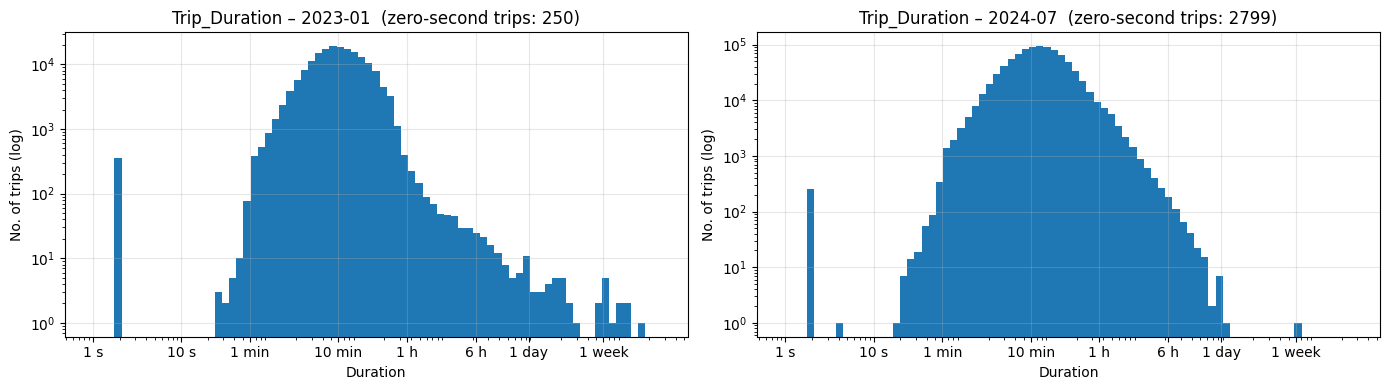

In [17]:
# Histogram with log-spaced bins (1 second to 30 days). Zero-second trips cannot be plotted on a log axis and are counted separately.
bins = np.logspace(0, np.log10(30 * 86400), 80)
ticks = [1, 10, 60, 600, 3600, 6*3600, 86400, 7*86400]
tick_labels = ["1 s", "10 s", "1 min", "10 min", "1 h", "6 h", "1 day", "1 week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ["2023-01", "2024-07"]):
    d = samples[name]["Trip_Duration"]
    ax.hist(d[d > 0], bins=bins)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
    ax.set_title(f"Trip_Duration – {name}  (zero-second trips: {(d == 0).sum()})")
    ax.set_xlabel("Duration"); ax.set_ylabel("No. of trips (log)")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
- There is a tall spike at the far left (trips of 1 to 3 seconds). These are the invalid trips (dock re-locking). After that, there are almost no trips between 3 seconds and about 1 minute. Then the main graph of real rides rising from about 1 minute and peaking around 10 minutes.
- On the right side of the graph, the number of trips curve downward from about 30 minutes to a few hours. Then, we see scattered bars from around 1 day and beyond. This is the upper side of outliers/invalid trips that cannot be real rides. These may be bikes that were not returned (or returned without being docked properly).
- The gap on the left between 3 s and 1 min is where we can put the threshold for a short-trip cutoff.
- On the upper limit (long-trip cutoff), we should check other months or the full Trip Duration dataset.

### 2.3 Candidate Cutoffs (Too short and too long trips)

To decide the threshold for too-short and too-long trips, we count how many trips fall below several short cutoffs and above several long cutoffs

In [18]:
# Count and % of trips shorter than / longer than each candidate cutoff, for the sample months
short_cuts = {"< 3 s": 3, "< 10 s": 10, "< 30 s": 30, "< 1 min": 60, "< 2 min": 120}
long_cuts  = {"> 1 h": 3600, "> 2 h": 7200, "> 3 h": 10800, "> 6 h": 21600, "> 12 h": 43200, "> 1 day": 86400, "> 1 week": 604800}

rows = []
for name, df in samples.items():
    d = df["Trip_Duration"]; n = len(d)
    r = {"month": name, "trips": n}
    for label, cut in short_cuts.items():
        r[label] = f"{(d < cut).sum():,} ({(d < cut).mean()*100:.2f}%)"
    for label, cut in long_cuts.items():
        r[label] = f"{(d > cut).sum():,} ({(d > cut).mean()*100:.3f}%)"
    rows.append(r)
pd.DataFrame(rows).set_index("month").T

month,2023-01,2024-01,2024-07,2025-01,2026-01
trips,180135,204879,906372,202946,137336
< 3 s,601 (0.33%),403 (0.20%),"3,052 (0.34%)",397 (0.20%),"1,169 (0.85%)"
< 10 s,601 (0.33%),403 (0.20%),"3,053 (0.34%)",398 (0.20%),"1,169 (0.85%)"
< 30 s,604 (0.34%),406 (0.20%),"3,077 (0.34%)",401 (0.20%),"1,172 (0.85%)"
< 1 min,666 (0.37%),475 (0.23%),"3,424 (0.38%)",512 (0.25%),"1,213 (0.88%)"
< 2 min,"3,168 (1.76%)","3,304 (1.61%)","12,597 (1.39%)","3,372 (1.66%)","2,636 (1.92%)"
> 1 h,924 (0.513%),"1,921 (0.938%)","24,263 (2.677%)",527 (0.260%),397 (0.289%)
> 2 h,369 (0.205%),385 (0.188%),"5,042 (0.556%)",134 (0.066%),116 (0.084%)
> 3 h,257 (0.143%),255 (0.124%),"1,977 (0.218%)",87 (0.043%),60 (0.044%)
> 6 h,131 (0.073%),165 (0.081%),381 (0.042%),45 (0.022%),42 (0.031%)


**OBSERVATIONS:**
1. Short side:
- Counts under 3s up until under 1 minute are almost the same. Nearly all trips that are shorter than 1 minute are only a few seconds long. (Load re-docking case)
- Between 1 and 2 minutes, the count jumps to 1.4 to 1.9% of trips which may indicate that these are real short rides (ex. riding for very short distances or a couple of streets).
- The percentage of very short trips is higher in January 2026 (0.85%) than in the other months (0.2 to 0.4%).
2. Long side:
- Trips over 1 hour are 0.3% in January month but 2.7% of July 2024. This is not unusual because riders are more likely to ride long distances for leisure or tourism in warmer months.
- Over 3 hours the percentage of rides is 0.04 to 0.22%.
- Trips that are over 1 day are at most 0.03%.



### 2.4 Trips that start and end at the same station

A trip that starts and ends at the same station can be real (a round trip) or a dock re-lock (someone took a bike out, found a problem and put it straight back). We can use the trip duration to check this.

In [19]:
# Same-station trips and their durations
for name, df in samples.items():
    same = df[df["Start_Station_Id"] == df["End_Station_Id"]]
    print(f"\n{name}: same-station trips = {len(same):,} ({len(same)/len(df)*100:.1f}% of trips)")
    print("   of which under 1 min:", (same["Trip_Duration"] < 60).sum(),
          " | under 2 min:", (same["Trip_Duration"] < 120).sum(),
          " | median duration:", human(same["Trip_Duration"].median()))


2023-01: same-station trips = 4,620 (2.6% of trips)
   of which under 1 min: 34  | under 2 min: 870  | median duration: 13.4 min

2024-01: same-station trips = 4,464 (2.2% of trips)
   of which under 1 min: 47  | under 2 min: 751  | median duration: 14.5 min

2024-07: same-station trips = 29,213 (3.2% of trips)
   of which under 1 min: 148  | under 2 min: 2876  | median duration: 24.9 min

2025-01: same-station trips = 2,990 (1.5% of trips)
   of which under 1 min: 26  | under 2 min: 732  | median duration: 10.4 min

2026-01: same-station trips = 1,823 (1.3% of trips)
   of which under 1 min: 53  | under 2 min: 465  | median duration: 9.6 min


### 2.5 Time consistency: does End_Time minus Start_Time match Trip_Duration?

In [21]:
# Compare the duration of the timestamps with the Trip_Duration column
for name, df in samples.items():
    timestamps_duration = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    diff = (timestamps_duration - df["Trip_Duration"]).abs()
    print(f"\n{name}:")
    print("   End_Time before Start_Time:     ", (timestamps_duration < 0).sum())
    print("   |timestamps_duration - Trip_Duration| > 60 s:", (diff > 60).sum(), f"({(diff > 60).mean()*100:.3f}%)")
    print("   rows where End_Time is missing:  ", df["End_Time"].isna().sum())
    print("   zero-second trips:               ", (df["Trip_Duration"] == 0).sum())


2023-01:
   End_Time before Start_Time:      0
   |timestamps_duration - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   0
   zero-second trips:                250

2024-01:
   End_Time before Start_Time:      0
   |timestamps_duration - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   4
   zero-second trips:                183

2024-07:
   End_Time before Start_Time:      0
   |timestamps_duration - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   2170
   zero-second trips:                2799

2025-01:
   End_Time before Start_Time:      0
   |timestamps_duration - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   26
   zero-second trips:                166

2026-01:
   End_Time before Start_Time:      0
   |timestamps_duration - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   42
   zero-second trips:                347


In [22]:
# The rows with a missing End_Time: what does Trip_Duration look like for them?
df = samples["2024-07"]
no_end_time = df["End_Time"].isna()
print("Rows with missing End_Time:", no_end_time.sum())
print("Their Trip_Duration values:", df.loc[no_end_time, "Trip_Duration"].value_counts().to_dict())
print("Of these, also missing End_Station_Id:", (no_end_time & df["End_Station_Id"].isna()).sum())

Rows with missing End_Time: 2170
Their Trip_Duration values: {0: 2170}
Of these, also missing End_Station_Id: 928


**OBSERVATIONS:**
- The timestamps and `Trip_Duration` agree (0 rows differ by more than 60 s) and no trip ends before it starts.
- Every row with a missing `End_Time` has a `Trip_Duration` of **0 seconds**: these are incomplete trip records (the trip never properly ended), not real rides.
- Zero-second trips: 166 to 2,799 per sample month (0.1 to 0.3%).

### 2.6 Station ids and names

In [23]:
# How many distinct stations, and do any station ids have more than one name inside the same month?
for name, df in samples.items():
    n_start = df["Start_Station_Id"].nunique()
    names_per_id = df.groupby("Start_Station_Id")["Start_Station_Name"].nunique()
    print(f"{name}: distinct start stations = {n_start:,}  | ids with more than one name in the month = {(names_per_id > 1).sum()}"
          f"  | rows with a missing Start_Station_Name = {df['Start_Station_Name'].isna().sum():,}")

2023-01: distinct start stations = 651  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 10,630
2024-01: distinct start stations = 773  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2024-07: distinct start stations = 826  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2025-01: distinct start stations = 848  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2026-01: distinct start stations = 918  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0


**OBSERVATIONS:**
1. The number of unique start stations grew:
- January 2023: 651
- January 2026: 918
- This is part of the growth plan of Bike Share Toronto. Station IDs that appear in later years only are the new stations that were added.
2. Station ID names are consistent:
- No station id has two different names inside a month.
The 10,630 missing `Start_Station_Name` values in Jan 2023 are missing names only. The ids are present, so trips can still be counted per station. We can just use Station IDs and remove Station Names as a feature.
3. No duplicate `Trip_Id`

## 3. Profiling All 39 Months

We ran the same checks over every month to compare the findings from the sample months to the rest of the dataset. The following loop reads one file at a time, computes the information needed and discards the original data from memory afterwards. The results are saved to `data/profile/`.

### 3.1 Helper functions

In [24]:
def load_raw_month(path):
    """Read one monthly file, standardize the column names and parse the dates. No rows are removed."""
    df = pd.read_csv(path, low_memory=False)
    df = standardize_columns(df)
    df = parse_times(df)
    return df

def profile_month(df, year, month):
    """Compute the checks from Sections 1 and 2 for one month and return them as a dictionary (one row of the profile table)."""
    d = df["Trip_Duration"]
    implied = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    month_start = pd.Timestamp(year=year, month=month, day=1)
    month_end = month_start + pd.offsets.MonthBegin(1)

    row = {"year": year, "month": month, "rows": len(df),
           "duplicate_trip_id": int(df["Trip_Id"].duplicated().sum()),
           "same_bike_same_start": int(df.duplicated(subset=["Bike_Id", "Start_Time"]).sum()),
           "start_time_unparsed": int(df["Start_Time"].isna().sum()),
           "start_outside_month": int(((df["Start_Time"] < month_start) | (df["Start_Time"] >= month_end)).sum()),
           "end_before_start": int((implied < 0).sum()),
           "time_mismatch_gt60s": int(((implied - d).abs() > 60).sum()),
           "zero_duration": int((d == 0).sum()),
           "same_station": int((df["Start_Station_Id"] == df["End_Station_Id"]).sum()),
           "same_station_lt60s": int(((df["Start_Station_Id"] == df["End_Station_Id"]) & (d < 60)).sum()),
           "n_start_stations": int(df["Start_Station_Id"].nunique()),
           "n_end_stations": int(df["End_Station_Id"].nunique()),
           "n_bikes": int(df["Bike_Id"].nunique()),
           "casual": int((df["User_Type"].isin(["Casual", "Casual Member"])).sum()),
           "member": int((df["User_Type"].isin(["Member", "Annual Member"])).sum()),
           "ebike": int(df["Bike_Model"].isin(["EFIT", "EFIT G5", "ASTRO"]).sum()),
           }
    for col in STANDARD_COLUMNS:                                  # missing values per column
        row[f"miss_{col}"] = int(df[col].isna().sum())
    for label, cut in short_cuts.items():                          # candidate short cutoffs
        row[f"lt_{cut}s"] = int((d < cut).sum())
    for label, cut in long_cuts.items():                           # candidate long cutoffs
        row[f"gt_{cut}s"] = int((d > cut).sum())
    for p in [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]:
        row[f"dur_p{p*100:g}"] = float(d.quantile(p))
    row["dur_min"] = int(d.min()); row["dur_max"] = int(d.max()); row["dur_mean"] = float(d.mean())
    return row

### 3.2 Run the loop over every monthly file

In [25]:
PROFILE_FILE = f"{PROFILE}/profile_by_month.csv"
STATION_FILE = f"{PROFILE}/station_months.csv"       # one row per station per month: used later for the station first-seen table
HIST_FILE    = f"{PROFILE}/tripdur_hist.npy"        # histogram counts of Trip_Duration: row 0 = training years 2023-2024, row 1 = test years 2025-2026

TRAIN_YEARS = [2023, 2024]        # the project's training years; 2025 is the test year and 2026 Q1 the final check

if os.path.exists(PROFILE_FILE) and os.path.exists(STATION_FILE) and os.path.exists(HIST_FILE):
    profile = pd.read_csv(PROFILE_FILE)
    station_months = pd.read_csv(STATION_FILE)
    hist_train, hist_test = np.load(HIST_FILE)
    print("Loaded the saved profile:", profile.shape)
else:
    profile_rows, station_rows = [], []
    hist_train, hist_test = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
    for _, f in file_table.iterrows():
        path = f"{RAW}/{f['year']}/{f['file']}"
        df = load_raw_month(path)
        profile_rows.append(profile_month(df, f["year"], f["month"]))
        # station x month counts (start stations), with the most common name for the id that month
        sm = (df.groupby("Start_Station_Id")
                .agg(trips=("Trip_Id", "size"), name=("Start_Station_Name", lambda s: s.mode().iloc[0] if s.notna().any() else np.nan))
                .reset_index())
        sm["year"], sm["month"] = f["year"], f["month"]
        station_rows.append(sm)
        d = df["Trip_Duration"]
        h = np.histogram(d[d > 0], bins=bins)[0]
        if f["year"] in TRAIN_YEARS:
            hist_train += h
        else:
            hist_test += h
        print(f"{f['year']}-{f['month']:02d}: {len(df):>9,} rows   done")
    profile = pd.DataFrame(profile_rows)
    station_months = pd.concat(station_rows, ignore_index=True)
    profile.to_csv(PROFILE_FILE, index=False)
    station_months.to_csv(STATION_FILE, index=False)
    np.save(HIST_FILE, np.vstack([hist_train, hist_test]))
    print("Saved:", PROFILE_FILE)

profile["year_month"] = profile["year"].astype(str) + "-" + profile["month"].astype(str).str.zfill(2)
profile["split"] = np.where(profile["year"].isin(TRAIN_YEARS), "train 2023-24", "test 2025-26")
TOTAL_ROWS = profile["rows"].sum()
TOTAL_TRAIN = profile.loc[profile["split"] == "train 2023-24", "rows"].sum()
TOTAL_TEST = TOTAL_ROWS - TOTAL_TRAIN
print("Total trips in all 39 files:", f"{TOTAL_ROWS:,}", f"  (training years {TOTAL_TRAIN:,}, test years {TOTAL_TEST:,})")

Loaded the saved profile: (39, 53)
Total trips in all 39 files: 21,030,828   (training years 12,666,235, test years 8,364,593)


### 3.3 Totals by year (2023-2026)

In [26]:
# Rows, duplicates and the consistency checks, summed per year
check_cols = ["rows", "duplicate_trip_id", "same_bike_same_start", "start_time_unparsed", "start_outside_month",
              "end_before_start", "time_mismatch_gt60s", "zero_duration", "same_station", "same_station_lt60s"]
by_year = profile.groupby("year")[check_cols].sum()
by_year.loc["TOTAL"] = by_year.sum()
by_year

,rows,duplicate_trip_id,same_bike_same_start,start_time_unparsed,start_outside_month,end_before_start,time_mismatch_gt60s,zero_duration,same_station,same_station_lt60s
year,,,,,,,,,,
2023,5713141,0,20,0,0,49,104,4396,183612,1004
2024,6953094,0,87,0,0,47,112,10873,187477,997
2025,7812520,0,143,0,0,176,266,5479,247238,2185
2026,552073,0,105,0,0,0,32,1535,8376,209
TOTAL,21030828,0,355,0,0,272,514,22283,626703,4395


In [27]:
# Missing values per column as a % of rows, per year
miss_cols = [c for c in profile.columns if c.startswith("miss_")]
miss_pct = profile.groupby("year")[miss_cols].sum().div(profile.groupby("year")["rows"].sum(), axis=0) * 100
miss_pct.columns = [c.replace("miss_", "") for c in miss_pct.columns]
miss_pct.round(3).T

year,2023,2024,2025,2026
Trip_Id,0.000,0.000,0.000,0.000
Trip_Duration,0.000,0.000,0.000,0.000
Start_Station_Id,0.000,0.000,0.000,0.000
Start_Time,0.000,0.000,0.000,0.000
Start_Station_Name,10.416,0.000,0.000,0.000
End_Station_Id,0.052,0.121,0.087,0.269
End_Time,0.000,0.084,0.014,0.090
End_Station_Name,10.477,0.121,0.012,0.269
Bike_Id,0.000,0.000,0.000,0.000
User_Type,0.000,0.000,0.000,0.000


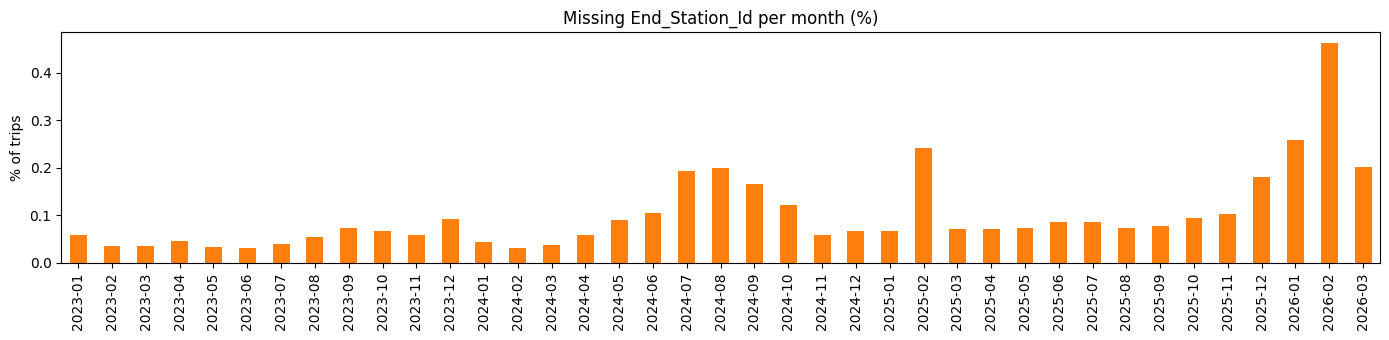

In [28]:
# Missing End_Station_Id per month, as a %
profile["miss_end_pct"] = profile["miss_End_Station_Id"] / profile["rows"] * 100
ax = profile.plot(x="year_month", y="miss_end_pct", kind="bar", figsize=(14, 3.5), legend=False, color="tab:orange")
ax.set_ylabel("% of trips"); ax.set_xlabel(""); ax.set_title("Missing End_Station_Id per month (%)")
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
1. Total trips: **21,030,828 trips** (12,666,235 in 2023-2024).
- No duplicate `Trip_Id` in any month.
- 355 rows (0.002%) share a bike and a start time.
2. Daylight saving clock changes affected timestamps (March, November):
- `end_before_start` (272 rows) occured in November (2023: 49, 2024: 47, 2025: 176)
- `time_mismatch_gt60s` (514 rows) are in March and November (2023: 104, 2024: 112, 2025: 266, 2026: 32). Those may be due to daylight-saving clock changes.
- The timestamps are off by one hour but `Trip_Duration` shows the actual length of the trips. These are real trips, so we shouldn't just remove them as errors. **Note to the group: Consider the daylight saving clock changes when analyzing the departures and arrivals in these months.**
3. Missing Values
- There are very few missing values except for two columns:
  - `Start_Station_Name` is missing in 10.4% of 2023 rows (names only; ids are complete)
  - `Bike_Model` does not exist in 2023.
  - `End_Station_Id` is missing in 0.05 to 0.27% of rows per year and peaks in the summer of 2024 (bar chart).
  - `End_Time` is missing in 0.01 to 0.09% of rows from 2024 and with a zero duration.

**Note:**
- We won't be using `Bike_Model` since it doesn't exist in 2023 and we cannot form an analysis on this given our training dataset.

### 3.4 Trips per month, user type share, stations per month

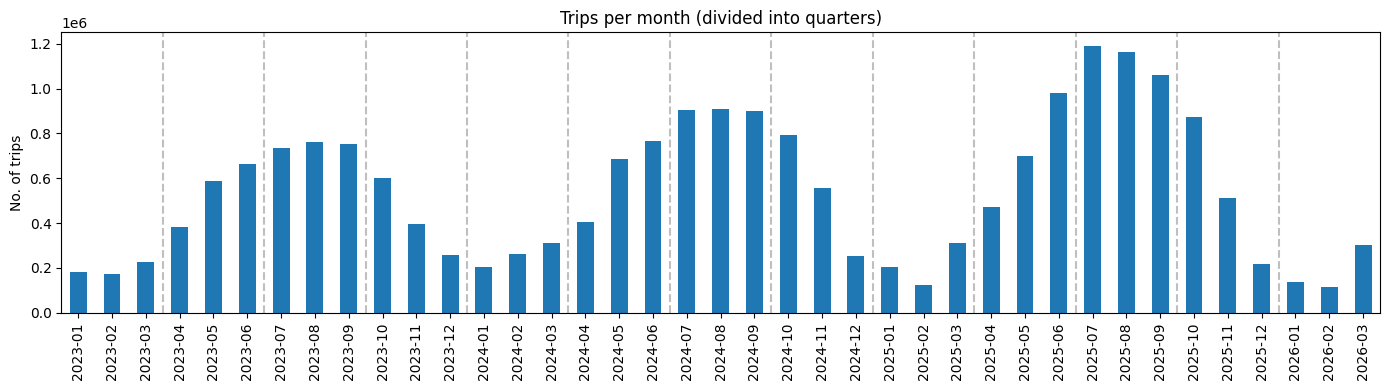

In [29]:
# Trips per month across all years.
ax = profile.plot(x="year_month", y="rows", kind="bar", figsize=(14, 4), legend=False)
for i, ym in enumerate(profile["year_month"]):
    if ym.endswith(("-01", "-04", "-07", "-10")):
        ax.axvline(i - 0.5, color="grey", linestyle="--", alpha=0.5)
ax.set_ylabel("No. of trips"); ax.set_xlabel(""); ax.set_title("Trips per month (divided into quarters)")
plt.tight_layout(); plt.show()

In [30]:
# Trips per year and per quarter
profile["quarter"] = "Q" + ((profile["month"] - 1) // 3 + 1).astype(str)
print("Trips per year:")
print(profile.groupby("year")["rows"].sum().map("{:,}".format))
print("\nTrips per quarter (all years):")
print(profile.groupby("quarter")["rows"].sum().map("{:,}".format))

Trips per year:
year
2023    5,713,141
2024    6,953,094
2025    7,812,520
2026      552,073
Name: rows, dtype: object

Trips per quarter (all years):
quarter
Q1    2,549,589
Q2    5,641,912
Q3    8,384,292
Q4    4,455,035
Name: rows, dtype: object


In [31]:
# Casual vs member share and e-bike share per year
share = profile.groupby("year")[["rows", "casual", "member", "ebike"]].sum()
share["casual_%"] = (share["casual"] / share["rows"] * 100).round(1)
share["ebike_%"]  = (share["ebike"]  / share["rows"] * 100).round(1)
share

,rows,casual,member,ebike,casual_%,ebike_%
year,,,,,,
2023,5713141,5348784,364357,0,93.6,0.0
2024,6953094,1586909,5366185,1073937,22.8,15.4
2025,7812520,2141436,5671084,1513762,27.4,19.4
2026,552073,61170,490903,30234,11.1,5.5


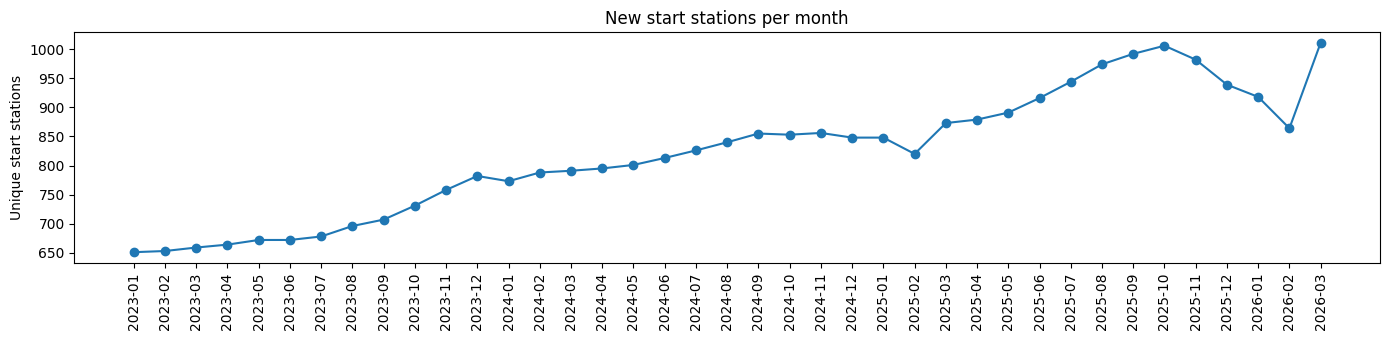

In [32]:
# New start stations per month (station network growth)
ax = profile.plot(x="year_month", y="n_start_stations", kind="line", marker="o", figsize=(14, 3.5), legend=False)
ax.set_ylabel("Unique start stations"); ax.set_xlabel(""); ax.set_title("New start stations per month")
ax.set_xticks(range(len(profile))); ax.set_xticklabels(profile["year_month"], rotation=90)
plt.tight_layout(); plt.show()

In [33]:
# Recheck the 2023 user type counts
profile[profile["year"] == 2023][["year_month", "rows", "casual", "member"]].assign(
    casual_pct=lambda t: (t["casual"] / t["rows"] * 100).round(1)).set_index("year_month").T

year_month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
rows,180135.0,172776.0,224545.0,380346.0,589217.0,663691.0,735924.0,760141.0,754303.0,601075.0,393873.0,257115.0
casual,130135.0,130015.0,173584.0,303161.0,506640.0,615182.0,723698.0,760003.0,754303.0,601075.0,393873.0,257115.0
member,50000.0,42761.0,50961.0,77185.0,82577.0,48509.0,12226.0,138.0,0.0,0.0,0.0,0.0
casual_pct,72.2,75.3,77.3,79.7,86.0,92.7,98.3,100.0,100.0,100.0,100.0,100.0


**OBSERVATIONS:**
1. Trip Volume: 2023: 5.71M, 2024: 6.95M
- The data also shows that trips continued to grow in 2025 and the first quarter of 2026.
2. Seasonal Rider Pattern:
- We can see a pattern of seasonal riders. The rides in Q3 (Jul-Sept) are highest and Q1 (Jan-Mar) are the lowest.
3. The 2023 `User_Type` column seems to have incorrect data. For 2023, 93.6% of trips were marked as casual and annual member count in September is 0. But in 2024 onwards, there are only ~23%+ of casual trips. We will not be analyzing user types in our project.
4. Stations: the number of active start stations rises steadily from 651 to 1,011. New stations will need to be flagged so that "growth" at a station that just opened is not confused with growing demand.

### 3.5 Trip_Duration: choosing the cutoffs from the training years

In [35]:
# Percentiles per year (seconds), training years only, using the median of the monthly values as a summary
pcols = ["dur_min", "dur_p0.1", "dur_p1", "dur_p5", "dur_p50", "dur_p95", "dur_p99", "dur_p99.9", "dur_max"]
profile[profile["year"].isin(TRAIN_YEARS)].groupby("year")[pcols].median().map(human)

,dur_min,dur_p0.1,dur_p1,dur_p5,dur_p50,dur_p95,dur_p99,dur_p99.9,dur_max
year,,,,,,,,,
2023,0 s,2 s,1.8 min,3.2 min,11.0 min,38.2 min,1.4 h,6.0 h,28.4 days
2024,0 s,1 s,1.8 min,3.2 min,10.7 min,35.2 min,1.2 h,4.1 h,11.6 days


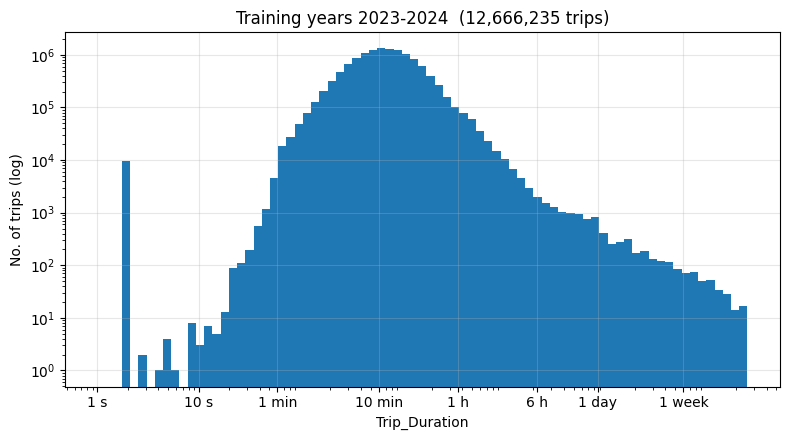

Zero-second trips (not on the log axis): 15,269


In [37]:
# Histogram of Trip_Duration (log-log), training years 2023-2024
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(bins[:-1], hist_train, width=np.diff(bins), align="edge")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
ax.set_xlabel("Trip_Duration"); ax.set_ylabel("No. of trips (log)")
ax.set_title(f"Training years 2023-2024  ({TOTAL_TRAIN:,} trips)")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
print("Zero-second trips (not on the log axis):",
      f"{profile.loc[profile['split']=='train 2023-24','zero_duration'].sum():,}")

In [38]:
# Check the training years to find the upper limit threshold.
tail = pd.DataFrame({"from": bins[:-1], "to": bins[1:], "trips": hist_train.astype(int)})
tail = tail[tail["from"] >= 3600].copy()
tail["from"] = tail["from"].map(human); tail["to"] = tail["to"].map(human)
tail["change vs previous bin"] = (tail["trips"] / tail["trips"].shift(1)).round(2)
tail.set_index("from").head(22)

,to,trips,change vs previous bin
from,,,
1.0 h,1.3 h,79318,NaN
1.3 h,1.5 h,60889,0.77
1.5 h,1.8 h,35113,0.58
1.8 h,2.2 h,22581,0.64
2.2 h,2.6 h,15004,0.66
2.6 h,3.2 h,10302,0.69
3.2 h,3.8 h,6664,0.65
3.8 h,4.6 h,4523,0.68
4.6 h,5.6 h,3003,0.66


**OBSERVATIONS:**
**Short trips cutoff**
- In 2023–2024 (12.7 M trips):
  - Less than 3 seconds: 24,928 trips
  - 3 seconds to 1 minute: 4,885
  - 1-2 minutes: 135,000
- A 1-minute cutoff would flag(remove) 0.235% of training trips. A 2-minute cutoff would flag 1.3% but would start removing real rides.

**Long trips cutoff**
- On the long-trips side, each bin in the table above shows that there a 60-70% change compared to the previous bit from ~1 hour to 6.7 hours, then plateaus until around 1 day (see the histogram).
- In 2023-2024:
  - more than 3 hours: 28,662 (0.23%)
  - more than 6 hours: 10,885 (0.09%)
  - more than 1 day: 2,599 (0.02%)

- We can choose either 3 hours or 6 hours as our upper threshold/cutoff since the percentage is very small, but to keep more real rides, we will choose the 6 hours.

## 4. Findings and Proposed Cleaning Rules

In [39]:
tr = profile[profile["split"] == "train 2023-24"]
n = TOTAL_TRAIN
def pct(col):
    a = tr[col].sum()
    return f"{a:,}  ({a/n*100:.3f}%)"
print(f"Total trips                           : {n:,}")
print(f"Duplicate Trip_Id                     : {tr['duplicate_trip_id'].sum():,}")
print(f"Trips under 1 min                     : {pct('lt_60s')}")
print(f"   of which under 3 s                 : {pct('lt_3s')}")
print(f"Trips over 3 h                        : {pct('gt_10800s')}")
print(f"Trips over 6 h                        : {pct('gt_21600s')}")
print(f"Missing End_Station_Id                : {pct('miss_End_Station_Id')}")
print(f"Missing End_Time (zero-duration rows) : {pct('miss_End_Time')}")
print(f"End before start + time mismatch      : {tr['end_before_start'].sum():,} + {tr['time_mismatch_gt60s'].sum():,}  ({(tr['end_before_start'].sum()+tr['time_mismatch_gt60s'].sum())/n*100:.4f}%)")
print(f"Missing Start_Station_Name, 2023 only : {tr.loc[tr.year==2023,'miss_Start_Station_Name'].sum():,}  ({tr.loc[tr.year==2023,'miss_Start_Station_Name'].sum()/tr.loc[tr.year==2023,'rows'].sum()*100:.1f}% of 2023 rows)")


Total trips                           : 12,666,235
Duplicate Trip_Id                     : 0
Trips under 1 min                     : 29,813  (0.235%)
   of which under 3 s                 : 24,928  (0.197%)
Trips over 3 h                        : 28,662  (0.226%)
Trips over 6 h                        : 10,885  (0.086%)
Missing End_Station_Id                : 11,368  (0.090%)
Missing End_Time (zero-duration rows) : 5,822  (0.046%)
End before start + time mismatch      : 96 + 216  (0.0025%)
Missing Start_Station_Name, 2023 only : 595,075  (10.4% of 2023 rows)


**Findings**
1. 2023 files have different formats from 2024-2026 files: Column names with spaces, no `Bike_Model`, dates as `mm/dd/yyyy HH:MM` with no seconds, and user labels `Casual Member` / `Annual Member`. We will standardize everything to the 2024 format.
2. `End_Station_Id` is read as a float (ex. `7130.0`) because of missing values. This is an ID, so we convert it to an integer.
3. The full dataset (training and test) has 39 files and 21,030,828 trips. Summer months have 4 to 5 times more trips than winter months.
4. There are no duplicate `Trip_Id` in any month.
5. Missing values (2023-2024):
  - `End_Station_Id`: 11,368 trips (0.05 to 0.12% per year)
  - `End_Time`: 5,822 trips, all with a trip duration of 0 seconds
  - `Start_Station_Name`: 10.4% of 2023 rows, but the IDs are all there
  - `Bike_Model`: does not exist in 2023
6. Trip duration
  - Very short trips (2023-2024):
    - Less than 3 seconds: 24,928 trips
    - 3 seconds to 1 minute: 4,885
    - 1 to 2 minutes: 135,000
  - Very long trips (2023-2024): the histogram goes down steadily until ~6.7 hours and then flattens out until 1 day and beyond (max is 28 days).
    - More than 3 hours: 28,662 (0.23%)
    - More than 6 hours: 10,885 (0.09%)
    - More than 1 day: 2,599 (0.02%)
  - 96 trips end before they start and 216 have timestamps that don't match `Trip_Duration`. All of these are in March and November (daylight saving). These are real trips.
7. `User_Type` values change: The 2023 `User_Type` values don't match 2024 onwards (93.6% casual in 2023 vs ~23% in 2024). We don't need this for the project, so we will not analyze user types.
8. Unique stations growth: The number of stations grows from 651 in January 2023 to 1,011 in March 2026.

**Cleaning rules**

We will flag the rows instead of deleting them, so we can still count them and decide separately what to include for departures and arrivals.

- **Rule 1 (R1) - Short trips:** Flag `Trip_Duration < 60 s` as `flag_short`. This also covers the rows with a missing `End_Time` since they all have a 0 second duration.
- **Rule 2 (R2) - Long trips:** Flag `Trip_Duration > 6 h` as `flag_long`. We chose 6 hours instead of 3 hours to keep more real rides.
- **Rule 3 (R3) - Missing end station:** A small amount of trips have no `End_Station_Id` but the departure still happened. Flag these as `flag_no_end`. We will keep them when counting departures and exclude them when counting arrivals.
- **Rule 4 (R4) - Duplicates:** No duplicates found. Drop exact duplicate `Trip_Id` if any appear.
- `is_valid` is True when none of the three flags is set.

Not flagged:
- Same-station trips are real round trips (median: 10 to 25 minutes), so we keep them.
- The daylight saving timestamp issues are real trips, so we keep them.  
  - Note: Always consider the daylight saving clock changes when counting departures and arrivals in March and November.

**Column decisions**
- Convert all months to the 2024 column names, parse the dates using the format for each year, and convert station IDs to `Int64`.
- Remove `Start_Station_Name` and `End_Station_Name` as features. We can just use the station IDs.
- We will not use `User_Type` or `Bike_Model` in the analysis.
- Flag new stations based on the month they first appear, so growth at a new station is not confused with growing demand.

**Note on data leakage:** The checks for schema, types, missing values and duplicates were run on all 39 months because the test data has to be cleaned with the same code. The cutoffs were chosen from the training years (2023-2024) only.


## 5. Cleaning the Data

We applied the cleaning rules and the column decisions to the 39 monthly files.
- Converted each month to 2024 column names, made the date formats consistent, and stored station IDs as `Int64`.
- Added the flags `flag_short`, `flag_long`, and `flag_no_end`, and the final `is_valid` flag so we can track which are the valid and invalid rows in the future.
- No rows removed except if there is an exact duplicate `Trip_Id`.
- Marked a station as new in the first month it appears in the data.
- Cleaned files are saved separately from the raw files, and the code creates a new profile file with the flag counts, so we can use it in later analysis.



In [ ]:
# 1. Additional setup for cleaning
CLEAN_DIR = f"{DATA}/clean"
os.makedirs(CLEAN_DIR, exist_ok=True)
raw_files = sorted(glob.glob(f"{RAW}/*/*.csv"))

FINAL_COLUMNS = ["Trip_Id", "Trip_Duration", "Start_Time", "End_Time",
                 "Start_Station_Id", "End_Station_Id",
                 "flag_short", "flag_long", "flag_no_end", "is_valid",
                 "is_new_start_station", "is_new_end_station"]

# 2. First month each station appears (start or end), used to flag new stations
station_first_seen = {}

for path in raw_files:
    file_match = re.search(r"(20\d\d)[-_](\d\d)", os.path.basename(path))
    year_month_key = f"{file_match.group(1)}-{file_match.group(2)}"

    # 2023 files use the old column names, so check which ones this file has
    sample_df = pd.read_csv(path, nrows=5)
    sample_df.columns = [c.replace("\ufeff", "") for c in sample_df.columns]
    start_col = "Start Station Id" if "Start Station Id" in sample_df.columns else "Start_Station_Id"
    end_col = "End Station Id" if "End Station Id" in sample_df.columns else "End_Station_Id"

    stations_chunk = pd.read_csv(path, usecols=[start_col, end_col])
    unique_start = stations_chunk[start_col].dropna().astype("Int64").unique()
    unique_end = stations_chunk[end_col].dropna().astype("Int64").unique()

    for station_id in set(unique_start).union(set(unique_end)):
        if station_id not in station_first_seen:
            station_first_seen[station_id] = year_month_key

print(f"Stations seen across all months: {len(station_first_seen)}")

# 3. Apply the cleaning rules to every month
summary_metrics = []

for path in raw_files:
    file_match = re.search(r"(20\d\d)[-_](\d\d)", os.path.basename(path))
    year, month = file_match.group(1), file_match.group(2)
    year_month_key = f"{year}-{month}"

    # Same loader as Section 3: standard column names and parsed dates
    df = load_raw_month(path)
    total_raw_rows = len(df)

    # Station ids as nullable integers
    df["Trip_Id"] = df["Trip_Id"].astype("Int64")
    df["Start_Station_Id"] = df["Start_Station_Id"].astype("Int64")
    df["End_Station_Id"] = df["End_Station_Id"].astype("Int64")

    # Rule 4: drop exact duplicate Trip_Id
    df = df.drop_duplicates(subset=["Trip_Id"])
    dropped_duplicates = total_raw_rows - len(df)

    # Rules 1 to 3: flag, do not delete
    df["flag_short"] = df["Trip_Duration"] < 60
    df["flag_long"] = df["Trip_Duration"] > 21600
    df["flag_no_end"] = df["End_Station_Id"].isna()
    df["is_valid"] = ~(df["flag_short"] | df["flag_long"] | df["flag_no_end"])

    # New station: first month it appears in the data
    df["is_new_start_station"] = df["Start_Station_Id"].map(station_first_seen) == year_month_key
    df["is_new_end_station"] = df["End_Station_Id"].map(station_first_seen) == year_month

    summary_metrics.append({
        "Year": int(year),
        "Month": int(month),
        "Year_Month": year_month_key,
        "Total_Raw_Trips": total_raw_rows,
        "Dropped_Duplicates": dropped_duplicates,
        "Flag_Short": df["flag_short"].sum(),
        "Flag_Long": df["flag_long"].sum(),
        "Flag_No_End": df["flag_no_end"].sum(),
        "Valid_Trips": df["is_valid"].sum(),
    })

    # Keep only the columns we will use and save one cleaned file per month
    df[FINAL_COLUMNS].to_csv(f"{CLEAN_DIR}/clean_ridership_{year}_{month}.csv", index=False)

# 4. Save the flag counts per month and show the totals by year
df_summary = pd.DataFrame(summary_metrics)
df_summary.to_csv(f"{PROFILE}/cleaning_summary_counts.csv", index=False)
print("Cleaned files saved to:", CLEAN_DIR)

by_year = df_summary.groupby("Year")[["Total_Raw_Trips", "Dropped_Duplicates",
                                       "Flag_Short", "Flag_Long", "Flag_No_End", "Valid_Trips"]].sum()
by_year.loc["TOTAL"] = by_year.sum()
by_year

## 6. The Target Variable


##